# 25 · When do profile components agree?

Audit the 13 finite-image coordinates, including the two orientation-removal controls, on the 16 held-out MNIST galleries. Rank agreement, shared misses and contribution to a fixed combination measure different notions of redundancy. All computations use the existing held-out pairs.

Fixed and aligned local Q have mean within-query rank correlation 0.835, yet share only 28 of the 283 exact-source misses made by either. For same-digit retrieval they share 1,145 of 1,623 misses.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.stage7 import METHODS, COMPONENTS, CONDITIONS, run
SOURCE=ROOT/'results'/'stage6'
OUT=ROOT/'results'/'stage7'
OUT.mkdir(exist_ok=True,parents=True)
plt.rcParams.update({'figure.dpi':110,'figure.constrained_layout.use':True,
                     'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()

Matplotlib is building the font cache; this may take a moment.


## Compare ranks within each query
For each view, remove the original and rank the 19 alternatives by distance. Compute a Spearman correlation across candidates for every pair of coordinates. Average those query correlations within each condition. Midranks handle ties after rounding at ten decimals. A constant rank vector makes its correlation undefined. The saved table reports how many of the 320 queries support every entry.

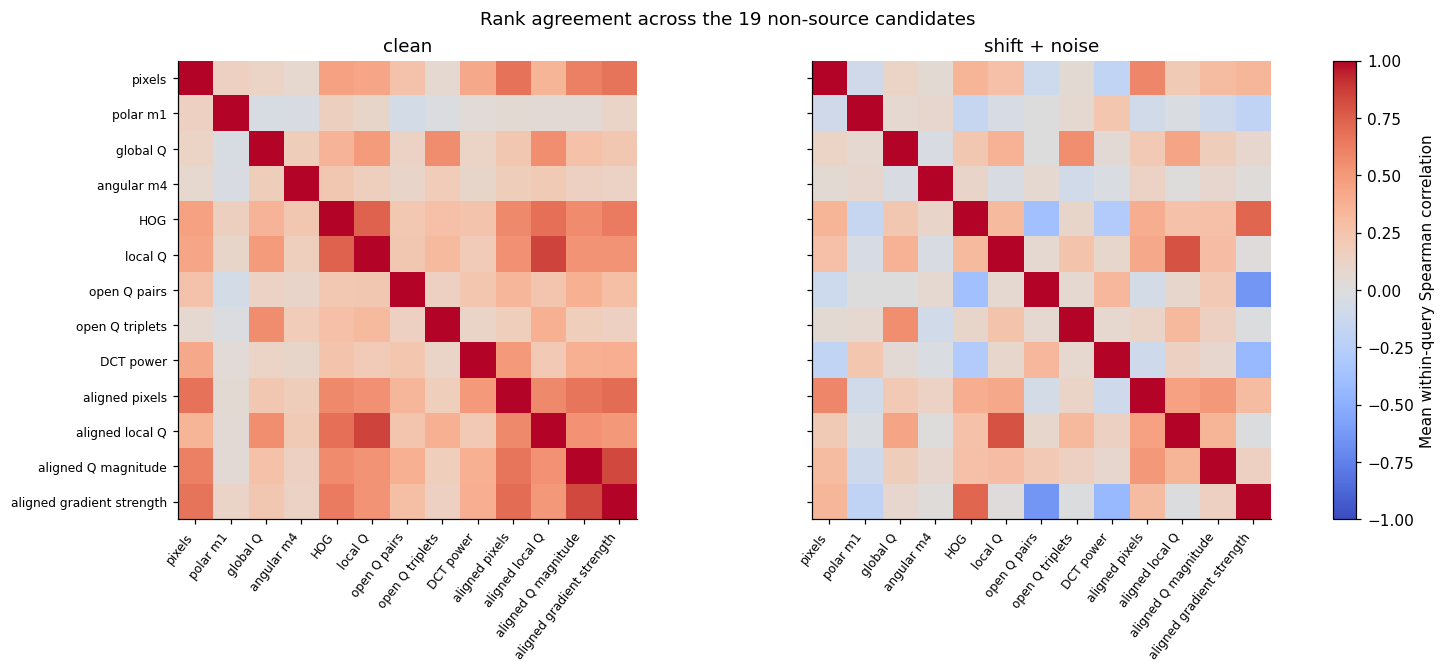

In [3]:
tables=run(SOURCE,OUT)
rank=tables['rank_redundancy']
fig,axes=plt.subplots(1,2,figsize=(13,6))
for i,(ax,condition) in enumerate(zip(axes,['clean','shift + noise'])):
    z=rank[rank.condition==condition].pivot(index='left',columns='right',values='mean_rho').loc[list(METHODS),list(METHODS)]
    im=ax.imshow(z,vmin=-1,vmax=1,cmap='coolwarm')
    ax.set_xticks(range(len(METHODS)),METHODS,rotation=52,ha='right',fontsize=8)
    ax.set_yticks(range(len(METHODS)),METHODS if i==0 else [],fontsize=8)
    ax.set_title(condition)
fig.colorbar(im,ax=axes,label='Mean within-query Spearman correlation')
fig.suptitle('Rank agreement across the 19 non-source candidates')
show('25_rank_redundancy')

## Compare rank similarity with decision overlap
A hard miss means that the correct candidate is absent from the top-score tie set. Partial top ties are tracked separately. Miss overlap is the intersection divided by the union of hard misses, pooled across the eight transformed conditions. The identity endpoint includes the original, while the class endpoint excludes it. The rank analysis above always excludes it so the exact-match candidate cannot inflate agreement.

In [5]:
selected=[('local Q','aligned local Q'),('pixels','aligned pixels'),
          ('aligned local Q','aligned Q magnitude'),('open Q pairs','open Q triplets')]
comparison=[]
for left,right in selected:
    r=rank[(rank.left==left)&(rank.right==right)].set_index('condition')
    comparison.append((left,right,r.mean_rho.mean(),r.loc['clean','mean_rho'],
                       r.loc['shift','mean_rho'],r.loc['shift + noise','mean_rho']))
display(pd.DataFrame(comparison,columns=['left','right','mean over conditions','clean','shift','shift + noise']).round(3))
overlap=tables['error_overlap']
display(overlap.query("left=='aligned local Q' and right in ['local Q','aligned pixels','aligned Q magnitude']")
        [['endpoint','left','right','left_misses','right_misses','shared_misses','miss_union','jaccard']].round(3))
print('Polar m1 has defined clean ranks for',
      rank.query("condition=='clean' and left=='polar m1' and right=='polar m1'").defined_queries.item(),
      'of 320 queries.')

,left,right,mean over conditions,clean,shift,shift + noise
0,local Q,aligned local Q,0.835,0.844,0.810,0.802
1,pixels,aligned pixels,0.663,0.678,0.523,0.584
2,aligned local Q,aligned Q magnitude,0.474,0.532,0.483,0.351
3,open Q pairs,open Q triplets,0.088,0.145,0.094,0.066


,endpoint,left,right,left_misses,right_misses,shared_misses,miss_union,jaccard
135,identity,aligned local Q,local Q,58,253,28,283,0.099
139,identity,aligned local Q,aligned pixels,58,104,44,118,0.373
141,identity,aligned local Q,aligned Q magnitude,58,94,43,109,0.394
304,class,aligned local Q,local Q,1401,1367,1145,1623,0.705
308,class,aligned local Q,aligned pixels,1401,1600,1214,1787,0.679
310,class,aligned local Q,aligned Q magnitude,1401,1681,1256,1826,0.688


Polar m1 has defined clean ranks for 277 of 320 queries.


## Interpretation
Fixed and aligned local Q agree strongly in their ranks, but have very different exact-source failure sets. Correlation across all alternatives is compatible with changing which candidate wins at the top. Pair and triplet correlations are weakly rank-correlated here, even though they derive from the same local Q field. This is empirical redundancy for the specified gallery and perturbations. It is distinct from an exact mathematical equivalence.